In [1]:
'''
PyTorch 1.0 强化学习 (Packt Publishing)
第2章：马尔可夫决策过程与动态规划
作者：Yuxi (Hayden) Liu
修改说明：修正了 T 矩阵的维度错误，增加了详细中文注释，优化了打印输出
'''

import torch
import matplotlib.pyplot as plt

# ==========================================
# 1. 定义 MDP 环境参数
# ==========================================

# 【状态转移矩阵 T】
# 修正维度为：[3个状态, 2个动作, 3个下一状态]
# 状态：0=study(学习), 1=sleep(睡觉), 2=play games(玩游戏)
# 动作：0=work(工作/努力), 1=slack(摸鱼/偷懒)
T = torch.tensor([
    # 从 s0 (study) 出发
    [[0.8, 0.1, 0.1],  # 执行 a0 (work)：80%留在study，10%去sleep，10%去play
     [0.1, 0.6, 0.3]], # 执行 a1 (slack)：10%去study，60%留在sleep，30%去play
    
    # 从 s1 (sleep) 出发
    [[0.7, 0.2, 0.1],  # 执行 a0 (work)
     [0.1, 0.8, 0.1]], # 执行 a1 (slack)
    
    # 从 s2 (play games) 出发
    [[0.6, 0.2, 0.2],  # 执行 a0 (work)
     [0.1, 0.4, 0.5]]  # 执行 a1 (slack)
])

# 【奖励函数 R】
# 对应 3 个状态的即时奖励：study(+1), sleep(0), play(-1)
R = torch.tensor([1., 0, -1.])

# 【折扣因子 gamma】
# 控制对未来奖励的重视程度，0.5 表示未来的奖励价值打五折
gamma = 0.5

# 【收敛阈值 threshold】
# 当两次迭代之间所有状态的价值变化都小于这个值时，认为已经收敛，停止迭代
threshold = 0.0001

In [2]:
# ==========================================
# 2. 定义策略
# ==========================================

# 【最优策略（假设）】
# 3个状态，2个动作。这里假设在所有状态下都 100% 选择 a0 (work)
policy_optimal = torch.tensor([[1.0, 0.0],
                               [1.0, 0.0],
                               [1.0, 0.0]])

# 【随机策略】
# 3个状态，2个动作。在所有状态下，50%概率选 work，50%概率选 slack
policy_random = torch.tensor([[0.5, 0.5],
                              [0.5, 0.5],
                              [0.5, 0.5]])

In [3]:
# ==========================================
# 3. 核心算法：策略评估 (Policy Evaluation)
# ==========================================

def policy_evaluation(policy, trans_matrix, rewards, gamma, threshold):
    """
    执行策略评估：计算给定策略下的状态价值函数 V
    原理：通过迭代应用贝尔曼期望方程，直到价值函数收敛
    
    参数:
        policy: 策略矩阵，形状为 [状态数, 动作数]，包含在每个状态下选择各动作的概率
        trans_matrix: 状态转移矩阵，形状为 [状态数, 动作数, 下一状态数]
        rewards: 奖励向量，形状为 [状态数]
        gamma: 折扣因子
        threshold: 收敛阈值
    返回:
        V: 收敛后的状态价值向量
    """
    n_state = policy.shape[0]  # 获取状态数量 (3)
    V = torch.zeros(n_state)   # 初始化所有状态的价值为 0
    
    iteration = 0  # 记录迭代次数
    
    while True:
        iteration += 1
        V_temp = torch.zeros(n_state)  # 临时存储本次迭代计算出的新价值
        
        # 遍历每一个状态
        for state, actions in enumerate(policy):
            # 遍历该状态下的每一个动作及其概率
            for action, action_prob in enumerate(actions):
                # 贝尔曼期望方程的核心计算：
                # V(s) = Σ π(a|s) * [ R(s) + γ * Σ P(s'|s,a) * V(s') ]
                # 
                # trans_matrix[state, action] 是一个长度为3的向量，表示从当前状态执行该动作后，转移到各下一状态的概率
                # torch.dot(...) 计算的是未来期望价值：Σ P(s'|s,a) * V(s')
                V_temp[state] += action_prob * (rewards[state] + gamma * torch.dot(trans_matrix[state, action], V))
        
        # 计算本次迭代与上一次迭代之间，所有状态价值的最大变化量
        max_delta = torch.max(torch.abs(V - V_temp))
        
        # 更新价值函数
        V = V_temp.clone()
        
        # 打印每次迭代的进度（可选，方便观察收敛过程）
        # print(f"  迭代 {iteration}: 最大变化量 = {max_delta:.6f}, 当前V = {V.numpy()}")
        
        # 如果最大变化量小于阈值，说明已经收敛，跳出循环
        if max_delta <= threshold:
            break
    
    print(f"  [收敛] 共迭代 {iteration} 次")
    return V

In [4]:
# ==========================================
# 4. 执行策略评估并打印结果
# ==========================================

print("=" * 60)
print("【场景一】评估最优策略（所有状态都选择 work）")
print("=" * 60)
V_optimal = policy_evaluation(policy_optimal, T, R, gamma, threshold)
print(f"最优策略下的状态价值函数 V:\n  s0(study): {V_optimal[0]:.4f}\n  s1(sleep): {V_optimal[1]:.4f}\n  s2(play):  {V_optimal[2]:.4f}\n")

print("=" * 60)
print("【场景二】评估随机策略（所有状态都 50% work, 50% slack）")
print("=" * 60)
V_random = policy_evaluation(policy_random, T, R, gamma, threshold)
print(f"随机策略下的状态价值函数 V:\n  s0(study): {V_random[0]:.4f}\n  s1(sleep): {V_random[1]:.4f}\n  s2(play):  {V_random[2]:.4f}\n")

【场景一】评估最优策略（所有状态都选择 work）
  [收敛] 共迭代 14 次
最优策略下的状态价值函数 V:
  s0(study): 1.6786
  s1(sleep): 0.6260
  s2(play):  -0.4821

【场景二】评估随机策略（所有状态都 50% work, 50% slack）
  [收敛] 共迭代 13 次
随机策略下的状态价值函数 V:
  s0(study): 1.2348
  s1(sleep): 0.2691
  s2(play):  -0.9013



In [5]:
# ==========================================
# 5. 带历史记录的策略评估（用于绘图）
# ==========================================

def policy_evaluation_history(policy, trans_matrix, rewards, gamma, threshold):
    """
    带历史记录的策略评估，用于绘制收敛曲线
    返回：最终价值 V，以及每次迭代的历史价值列表 V_his
    """
    n_state = policy.shape[0]
    V = torch.zeros(n_state)
    V_his = [V.clone()]  # 记录初始状态
    
    while True:
        V_temp = torch.zeros(n_state)
        for state, actions in enumerate(policy):
            for action, action_prob in enumerate(actions):
                V_temp[state] += action_prob * (rewards[state] + gamma * torch.dot(trans_matrix[state, action], V))
        
        max_delta = torch.max(torch.abs(V - V_temp))
        V = V_temp.clone()
        V_his.append(V.clone())  # 记录每次迭代后的价值
        
        if max_delta <= threshold:
            break
    return V, V_his


# 对最优策略进行带历史的评估
V_opt, V_history = policy_evaluation_history(policy_optimal, T, R, gamma, threshold)

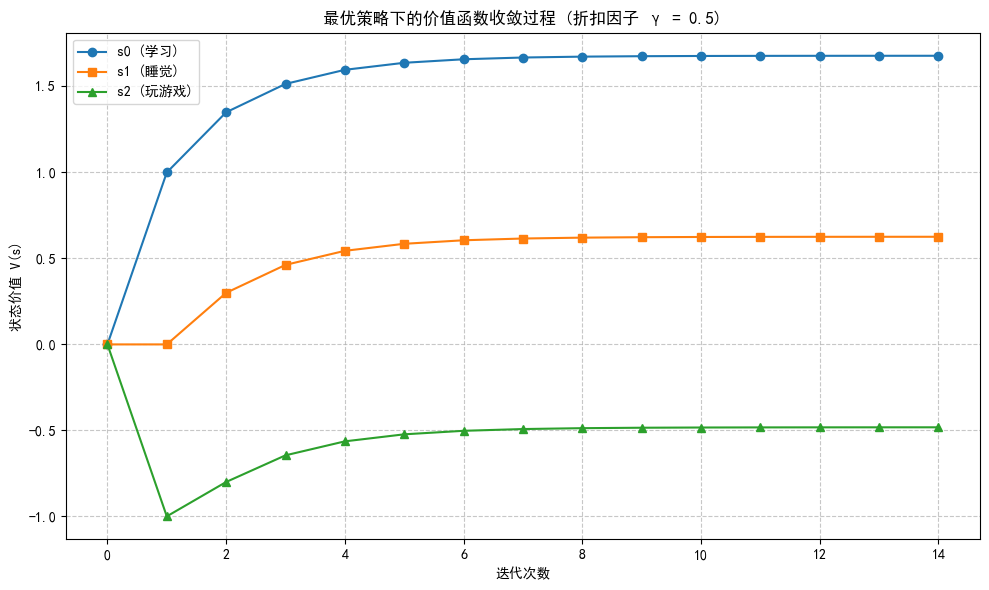

图表已生成并显示！


In [6]:
# ==========================================
# 6. 绘制收敛曲线
# ==========================================

# 解决 matplotlib 中文乱码问题
plt.rcParams['font.sans-serif'] = ['SimHei']  # 正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号

plt.figure(figsize=(10, 6))

# 从历史记录中提取每个状态的价值序列
s0_values = [v[0].item() for v in V_history]
s1_values = [v[1].item() for v in V_history]
s2_values = [v[2].item() for v in V_history]

# 绘制折线图
line_s0, = plt.plot(s0_values, marker='o', label='s0 (学习)')
line_s1, = plt.plot(s1_values, marker='s', label='s1 (睡觉)')
line_s2, = plt.plot(s2_values, marker='^', label='s2 (玩游戏)')

plt.title(f'最优策略下的价值函数收敛过程 (折扣因子 γ = {gamma})')
plt.xlabel('迭代次数')
plt.ylabel('状态价值 V(s)')
plt.legend(loc="upper left")
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("图表已生成并显示！")

这段代码的核心逻辑非常清晰，它是强化学习中 **策略评估（Policy Evaluation）** 的标准实现。

简单来说，它的任务是：**给定一个固定的行为模式（策略），计算在这个模式下，每个状态的“长期价值”是多少。**


### 第一部分：定义 MDP 环境（第 1-30 行）
**讲了什么：** 搭建一个虚拟的“学习-睡觉-玩游戏”世界，定义好规则。
**怎么做的：**
1.  **定义状态转移矩阵 `T`**：
    *   这是一个三维张量 `[3, 2, 3]`，分别代表 `[当前状态, 动作, 下一状态]`。
    *   例如 `T[0, 0, 0] = 0.8` 表示：在 `study`（状态0）执行 `work`（动作0），有 80% 的概率还留在 `study`（状态0）。
2.  **定义奖励 `R`**：
    *   一个一维张量 `[1.0, 0, -1.0]`，分别对应 `study`（+1）、`sleep`（0）、`play`（-1）的即时反馈。
3.  **定义超参数**：
    *   `gamma = 0.5`：折扣因子，代表未来的奖励只值现在的一半。
    *   `threshold = 0.0001`：收敛阈值，当价值变化小于这个数时，认为计算完成。

---

### 第二部分：定义两种策略（第 32-45 行）
**讲了什么：** 设定两种不同的行为模式，用来对比。
**怎么做的：**
1.  **最优策略 `policy_optimal`**：
    *   矩阵 `[[1, 0], [1, 0], [1, 0]]`。
    *   含义：无论在哪种状态，都 **100% 选择动作 0（work）**。
2.  **随机策略 `policy_random`**：
    *   矩阵 `[[0.5, 0.5], [0.5, 0.5], [0.5, 0.5]]`。
    *   含义：无论在哪种状态，都 **50% 概率 work，50% 概率 slack（摸鱼）**。

---

### 第三部分：核心算法 `policy_evaluation`（第 47-90 行）
**讲了什么：** 这是代码的灵魂。它实现了**贝尔曼期望方程**的迭代求解，算出给定策略下的价值函数 $V(s)$。
**怎么做的：**
1.  **初始化**：把所有状态的初始价值 $V$ 设为 0。
2.  **进入 `while True` 循环（迭代更新）**：
    *   **双重遍历**：遍历每一个状态 `state`，再遍历该状态下的每一个动作 `action`。
    *   **核心公式计算**：
        ```python
        V_temp[state] += action_prob * (rewards[state] + gamma * torch.dot(trans_matrix[state, action], V))
        ```
        这行代码完美对应了数学公式：
        $$V(s) \leftarrow \sum_{a} \pi(a|s) \left[ R(s) + \gamma \sum_{s'} P(s'|s,a) V(s') \right]$$
        *   `action_prob` 就是 $\pi(a|s)$（选这个动作的概率）。
        *   `rewards[state]` 就是 $R(s)$（即时奖励）。
        *   `torch.dot(...)` 计算的是 $\sum P(s'|s,a) V(s')$（未来期望价值的加权和）。
    *   **检查收敛**：计算新旧价值的最大差值 `max_delta`。如果差值小于 `threshold`，说明价值已经稳定，跳出循环；否则继续下一轮迭代。

---

### 第四部分：执行评估并打印（第 92-105 行）
**讲了什么：** 分别用上面定义的两种策略，调用核心算法，看看结果差多少。
**怎么做的：**
1.  调用 `policy_evaluation(policy_optimal, ...)`，打印出最优策略下三个状态的价值。
2.  调用 `policy_evaluation(policy_random, ...)`，打印出随机策略下三个状态的价值。
    *   *预期结果*：最优策略的价值会明显高于随机策略，因为随机策略有 50% 概率会去“摸鱼”导致进入低价值状态。

---

### 第五部分：带历史记录的评估 `policy_evaluation_history`（第 107-135 行）
**讲了什么：** 为了画图，我们需要知道价值是**怎么一步步收敛**的，而不仅仅是最终结果。
**怎么做的：**
1.  逻辑和上面的 `policy_evaluation` 几乎一样。
2.  **关键区别**：增加了一个列表 `V_his`，每次迭代后，都把当前的 $V$ 存进去。
3.  最后返回最终价值 `V` 和完整的历史轨迹 `V_his`。

---

### 第六部分：数据可视化（第 137-末尾）
**讲了什么：** 把收敛过程画成折线图，直观展示学习过程。
**怎么做的：**
1.  **解决中文乱码**：设置 `plt.rcParams` 使用黑体。
2.  **数据提取**：从 `V_history` 中分别提取出 `s0`, `s1`, `s2` 三个状态在每次迭代中的价值序列。
3.  **绘图**：
    *   X轴：迭代次数。
    *   Y轴：状态价值 $V(s)$。
    *   画三条线，分别代表三个状态。
4.  **展示**：调用 `plt.show()` 弹出图表窗口。

---

### 总结
这段代码 **从上到下** 完成了一个完整的实验闭环：
**定义环境 → 设定策略 → 迭代计算价值 → 对比结果 → 记录过程 → 画图展示**。

它没有涉及“如何找到最优策略”（那是策略迭代或价值迭代做的事），它只负责 **“评估”** —— 即：如果一直这么干，长期收益是多少。
